# H2 ground-state example

This notebook mirrors `examples/scripts/01_h2_ground_state.py`.
It shows the smallest complete active-space calculation in the repo.

Goal:
- see what sub-`1 mEh` agreement looks like on the simplest possible molecule

What to notice:
- the `ccik_thick` result is effectively identical to exact CAS-FCI on this toy problem

Project status note:
- the current large-active-space production answer in this repo is the Quantum Package path with `connected_sd_fullq`, `abs_residual`, `ccik_thick`, and fixed-budget tuning of `fixed_store_keep` and `fixed_propagate_keep`
- these teaching notebooks stay small on purpose; they explain the ideas before the large-`N2` benchmark workflow

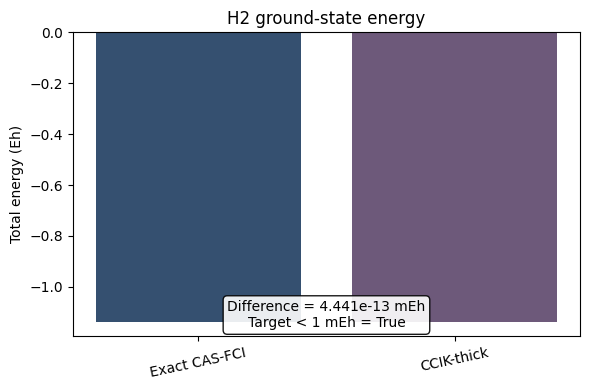

{'e_fci_total': -1.137283834488502,
 'e_ccik_total': -1.1372838344885015,
 'delta_millihartree': 4.440892098500626e-13}

In [1]:
import importlib.util
from pathlib import Path

import matplotlib.pyplot as plt

repo_root = Path.cwd()
if not (repo_root / "examples" / "scripts").exists():
    repo_root = repo_root.parent.parent
script_path = repo_root / "examples" / "scripts" / "01_h2_ground_state.py"
spec = importlib.util.spec_from_file_location("h2_example", script_path)
module = importlib.util.module_from_spec(spec)
assert spec is not None and spec.loader is not None
spec.loader.exec_module(module)

result = module.run_example()

fig, ax = plt.subplots(figsize=(6, 4))
labels = ["Exact CAS-FCI", "CCIK-thick"]
energies = [result["e_fci_total"], result["e_ccik_total"]]
colors = ["#355070", "#6d597a"]
ax.bar(labels, energies, color=colors)
ax.set_ylabel("Total energy (Eh)")
ax.set_title("H2 ground-state energy")
ax.text(
    0.5,
    0.03,
    f"Difference = {result['delta_millihartree']:.3e} mEh\nTarget < 1 mEh = {abs(result['delta_millihartree']) < 1.0}",
    transform=ax.transAxes,
    ha="center",
    bbox={"boxstyle": "round", "facecolor": "white", "alpha": 0.9},
)
plt.xticks(rotation=12)
plt.tight_layout()
plt.show()
result

## Where this fits in the project

This notebook is a small-system teaching example. The current production benchmark result for larger `N2` active spaces uses:

- Quantum Package backend
- `connected_sd_fullq`
- `abs_residual`
- `ccik_thick`
- `fixed_budget` compression

The detailed benchmark summary is in `docs/fixed_budget_results.md`.